# PharmaML — The Complete ML Workflow (Zero to One Hundred)

One notebook, every stage of a QSAR machine-learning project, in the order
you would actually run it:

| § | Stage | Toolkit |
|---|---|---|
| 1 | **Data entry** — import *your own* CSV/Excel | `pharmaml.data` |
| 2 | Exploratory analysis — audit, class balance, descriptor ranges | `pharmaml.viz` |
| 3 | Endpoint transformation — IC50 → pIC50 | `pharmaml.chem` |
| 4 | Split — stratified train/test | `pharmaml.ml` |
| 5 | Train — grid-searched random forest, CV folds | `pharmaml.ml` |
| 6 | Evaluate — confusion matrix, ROC, metrics table | `pharmaml.viz` |
| 7 | Multiclass — 3-class target end-to-end | `pharmaml.ml` |
| 8 | Regression — parity + residual diagnostics | `pharmaml.viz` |
| 9 | Leaderboard — every model, cross-validated | `pharmaml.ml` |
| 10 | Interpret — feature importance | `pharmaml.viz` |
| 11 | Deploy — save/load, score new compounds | `pharmaml.ml` |
| 12 | Publish — one-click HTML report + png/svg/pdf + csv/md/json | `pharmaml.viz` |

**Setup** — install the package with the plotting extra first:

```bash
pip install -e ".[reports]"
```

Every number below is generated from fixed seeds, so the notebook is fully
reproducible; replace the demo file in §1 with your own and re-run all cells.


In [1]:
import sys
import tempfile
from pathlib import Path

import numpy as np
import pandas as pd

from pharmaml import __version__

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 110)

# Scratch directory for this run's artifacts (use any path you like).
WORK = Path(tempfile.mkdtemp(prefix="ml_workflow_"))

print(f"pharmaml {__version__}")
print(f"artifacts -> {WORK}")

pharmaml 1.0.0
artifacts -> /tmp/ml_workflow_plle23ro


## 1 · Data entry — bring your own file

The legacy scripts hardcoded dataset filenames inside ~30 `.py` files.
`load_dataset` is the single entry point for **your** data: point `MY_FILE`
at any CSV/TSV/TXT/Excel file (delimiter sniffed automatically), and the
target column is auto-detected, the task inferred (classification with any
number of classes vs regression), non-numeric columns dropped *visibly*.

CLI equivalents:

```bash
pharmaml data inspect --data my_compounds.csv
pharmaml ml train    --data my_compounds.csv --task auto
```


In [2]:
# --- DEMO DATA ---------------------------------------------------------
# A realistic QSAR table: 8 descriptors, a 3-level activity target,
# plus SMILES/ID metadata columns that should NOT become features.
# (In your project: skip this cell and set MY_FILE to your own path.)
rng = np.random.default_rng(11)
n = 420
signal = rng.normal(size=(n, 3))
noise = rng.normal(scale=0.4, size=(n, 8))
descriptors = noise.copy()
descriptors[:, :3] += 0.6 * signal      # first 3 descriptors are informative
frame_demo = pd.DataFrame(descriptors, columns=[f"descr_{i:02d}" for i in range(8)])
score = frame_demo[["descr_00", "descr_01", "descr_02"]].sum(axis=1)
frame_demo["activity"] = np.where(
    score > np.quantile(score, 0.72), "active",
    np.where(score > np.quantile(score, 0.35), "weak", "inactive"),
)
frame_demo["SMILES"] = rng.choice(["CCO", "c1ccccc1O", "CC(=O)Oc1ccccc1C(=O)O"], size=n)
frame_demo["compound_id"] = [f"CMPD-{i:04d}" for i in range(n)]

MY_FILE = WORK / "my_compounds.csv"      # <- replace with your own file
frame_demo.to_csv(MY_FILE, index=False)
print(f"wrote demo table: {MY_FILE}  ({n} rows x {frame_demo.shape[1]} columns)")

wrote demo table: /tmp/ml_workflow_plle23ro/my_compounds.csv  (420 rows x 11 columns)


In [3]:
# --- THE ACTUAL IMPORT (works unchanged for your file) -----------------
from pharmaml.data import load_dataset

ds = load_dataset(MY_FILE)          # target auto-detected -> 'activity'

print(ds.summary())
print("\nfeature columns:", ds.feature_names)
print("dropped (non-numeric):", ds.dropped_columns)

Excluding 2 non-numeric column(s) from features: ['SMILES', 'compound_id']


source        : /tmp/ml_workflow_plle23ro/my_compounds.csv
shape         : 420 rows x 11 columns (8 numeric features)
target        : activity
task          : classification
missing cells : 0
dup. rows     : 0
classes (3): 'active': 118, 'inactive': 147, 'weak': 155
dropped cols  : SMILES, compound_id  [non-numeric]

feature columns: ['descr_00', 'descr_01', 'descr_02', 'descr_03', 'descr_04', 'descr_05', 'descr_06', 'descr_07']
dropped (non-numeric): ['SMILES', 'compound_id']


## 2 · Exploratory data analysis

Look at the data *before* modelling: the audit summary, the class balance
(one bar per class, counts annotated) and the descriptor distributions
(histogram grid with means marked) surface problems the legacy scripts
discovered as cryptic sklearn crashes.


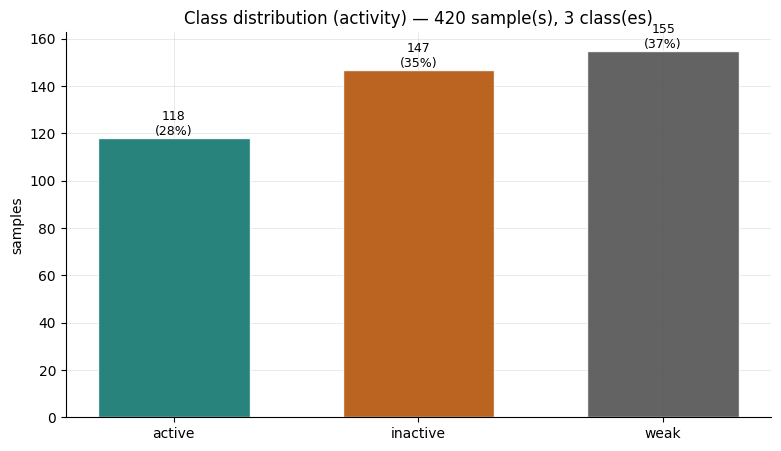

In [4]:
from pharmaml.viz import plot_class_distribution, plot_descriptor_distributions

fig_balance = plot_class_distribution(ds, title="Class distribution (activity)")

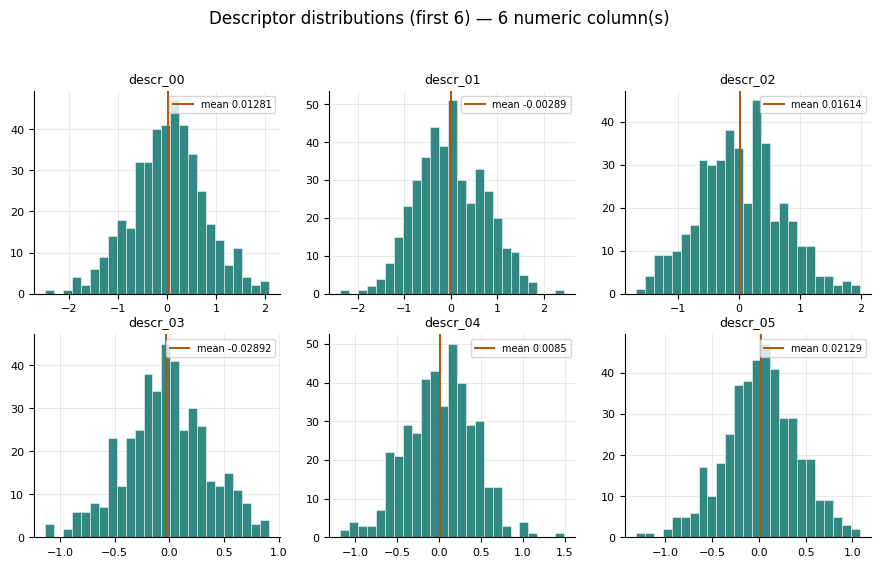

In [5]:
fig_dists = plot_descriptor_distributions(
    ds.X, columns=ds.feature_names[:6], title="Descriptor distributions (first 6)"
)

In [6]:
# Per-class quick statistics for one descriptor.
ds.frame.groupby("activity")["descr_00"].describe().round(3)

,count,mean,std,min,25%,50%,75%,max
activity,,,,,,,,
active,118.0,0.508,0.649,-0.970,0.072,0.453,0.906,2.081
inactive,147.0,-0.496,0.662,-2.496,-0.999,-0.448,-0.002,0.985
weak,155.0,0.119,0.591,-1.414,-0.264,0.113,0.497,1.610


## 3 · Endpoint transformation — IC50 → pIC50

Potency data arrives as IC50 (nM); models regress on the log-transformed
pIC50. `add_pic50_column` appends the converted column to any table.


In [7]:
from pharmaml.chem import add_pic50_column

potency = pd.DataFrame(
    {"compound": ["A", "B", "C", "D"],
     "IC50 (nM)": [12.0, 240.0, 1850.0, 92.0]}
)
converted = add_pic50_column(potency, source_col="IC50 (nM)")
converted.round(3)

,compound,IC50 (nM),pIC50
0,A,12.0,7.921
1,B,240.0,6.620
2,C,1850.0,5.733
3,D,92.0,7.036


## 4 · Train / test split

`make_train_test_split` stratifies by the target so every class appears in
both partitions with the same proportions.


In [8]:
from pharmaml.ml import make_train_test_split

X_train, X_test, y_train, y_test = make_train_test_split(
    ds.X, ds.y, test_size=0.2, random_state=42
)

split_audit = pd.DataFrame([
    {"partition": "train", "rows": len(y_train),
     **{f"n_{cls}": int((y_train == cls).sum()) for cls in ds.classes}},
    {"partition": "test", "rows": len(y_test),
     **{f"n_{cls}": int((y_test == cls).sum()) for cls in ds.classes}},
])
split_audit

,partition,rows,n_active,n_inactive,n_weak
0,train,336,94,118,124
1,test,84,24,29,31


## 5 · Train one model (with grid search)

`train_model` wraps the estimator in the impute+scale pipeline and runs a
5-fold cross-validated grid search; per-fold scores are returned so the
mean is never mistaken for a guarantee.


In [9]:
from pharmaml.ml import train_model

result = train_model(
    "random_forest", "classification", X_train, y_train, cv=5, tune=True
)
print(f"{result.name}: CV ROC-AUC = {result.cv_mean:.3f} ± {result.cv_std:.3f} "
      f"({result.fit_seconds:.1f}s)")
print("best params:", result.best_params)

random_forest: CV ROC-AUC = 0.916 ± 0.019 (30.6s)
best params: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 300}


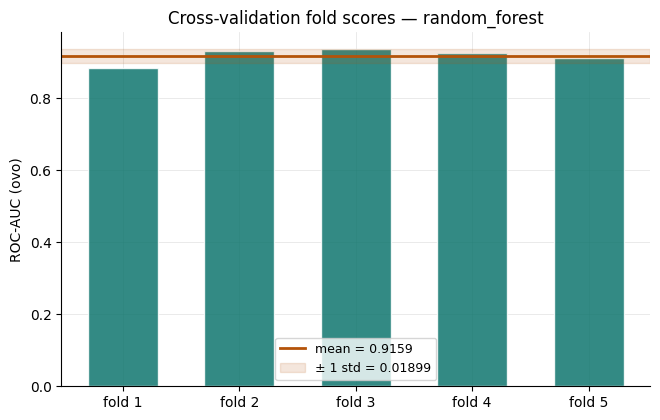

In [10]:
from pharmaml.viz import plot_cv_scores

fig_cv = plot_cv_scores(result, metric="ROC-AUC (ovo)")

## 6 · Evaluate the classifier

The `ClassificationReport` carries every metric plus the confusion matrix;
the plots below are the two figures the legacy scripts produced —
confusion heat-map and ROC curves — now multiclass-aware, with count/share
annotations and per-class one-vs-rest curves.


In [11]:
from pharmaml.ml import evaluate_model

report = evaluate_model(result.model, X_test, y_test, "classification")
print(report)

metrics_frame = (
    pd.DataFrame([report.as_dict()]).T.rename(columns={0: "value"}).round(4)
)
metrics_frame

accuracy=0.7619  balanced=0.7624  f1(macro)=0.7652  mcc=0.6406  roc_auc=0.9477  n=84


,value
accuracy,0.7619
balanced_accuracy,0.7624
f1_macro,0.7652
f1_weighted,0.7633
precision_macro,0.7688
recall_macro,0.7624
mcc,0.6406
roc_auc,0.9477
n_samples,84.0000


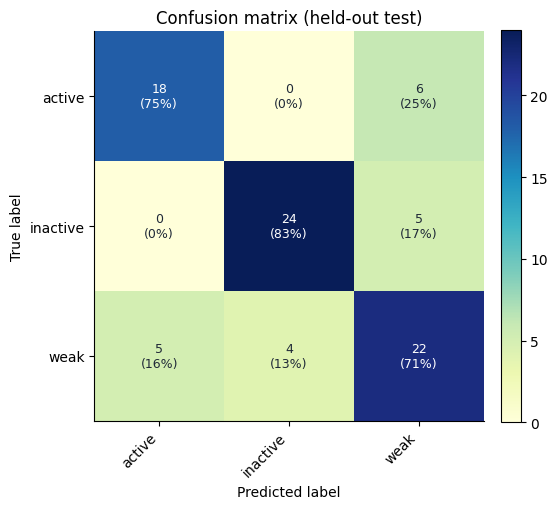

In [12]:
from pharmaml.viz import plot_confusion_matrix

fig_confusion = plot_confusion_matrix(report, title="Confusion matrix (held-out test)")

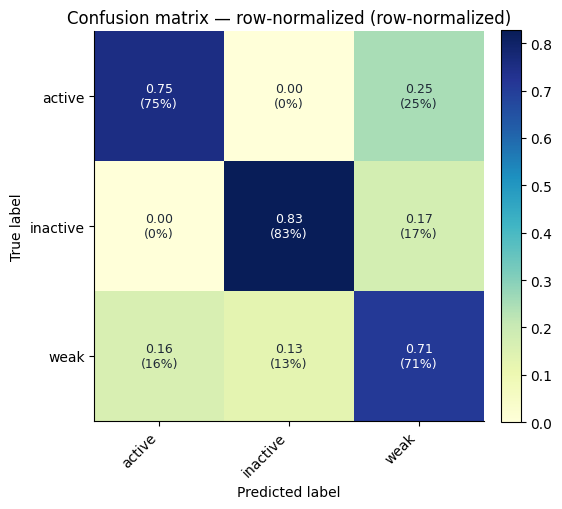

In [13]:
# Row-normalized view: per-class recall shares along the diagonal.
fig_confusion_norm = plot_confusion_matrix(
    report, normalize=True, title="Confusion matrix — row-normalized"
)

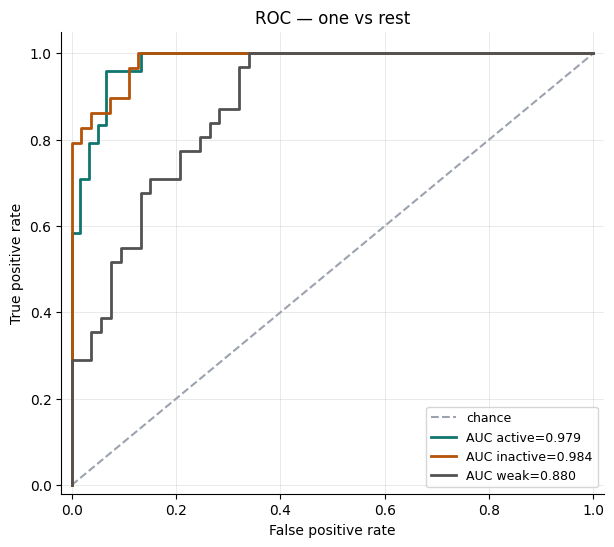

In [14]:
from pharmaml.viz import plot_roc_curves

fig_roc = plot_roc_curves(result.model, X_test, y_test, title="ROC — one vs rest")

## 7 · Multiclass — two or more classes

A target with 3+ distinct values is a first-class citizen: stratified
splits, k×k confusion matrix, one-vs-rest ROC per class, macro-averaged
metrics.


In [15]:
# A 3-class target with informative descriptors.
from sklearn.datasets import make_classification as _mk

X3, y3 = _mk(n_samples=360, n_features=8, n_informative=6, n_redundant=0,
             n_classes=3, n_clusters_per_class=1, flip_y=0.03, random_state=8)
multi = pd.DataFrame(X3, columns=[f"descr_{i:02d}" for i in range(8)])
multi["Target"] = np.array(["low", "medium", "high"])[y3]

ds_multi = load_dataset(multi.to_csv(WORK / "multiclass.csv", index=False) or WORK / "multiclass.csv")
print(ds_multi.summary())

source        : /tmp/ml_workflow_plle23ro/multiclass.csv
shape         : 360 rows x 9 columns (8 numeric features)
target        : Target
task          : classification
missing cells : 0
dup. rows     : 0
classes (3): 'high': 117, 'low': 121, 'medium': 122


3-class accuracy=0.822  f1_macro=0.822  roc_auc(ovr)=0.963


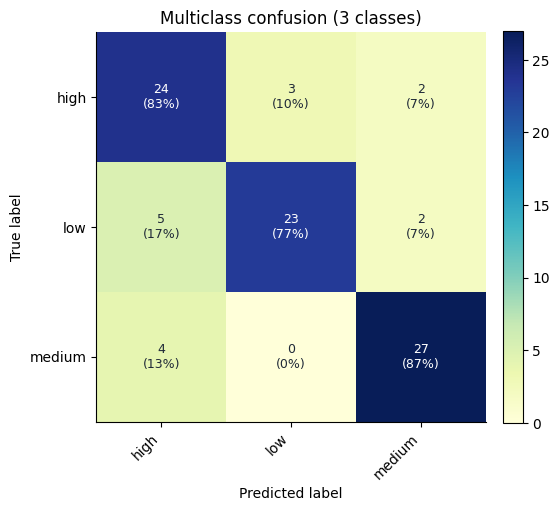

In [16]:
mX_tr, mX_te, my_tr, my_te = make_train_test_split(ds_multi.X, ds_multi.y, test_size=0.25)

mc = train_model("logistic_regression", "classification", mX_tr, my_tr, tune=False)
mc_report = evaluate_model(mc.model, mX_te, my_te, "classification")

print(f"3-class accuracy={mc_report.accuracy:.3f}  f1_macro={mc_report.f1_macro:.3f}  "
      f"roc_auc(ovr)={mc_report.roc_auc:.3f}")

fig_multi_confusion = plot_confusion_matrix(mc_report, title="Multiclass confusion (3 classes)")

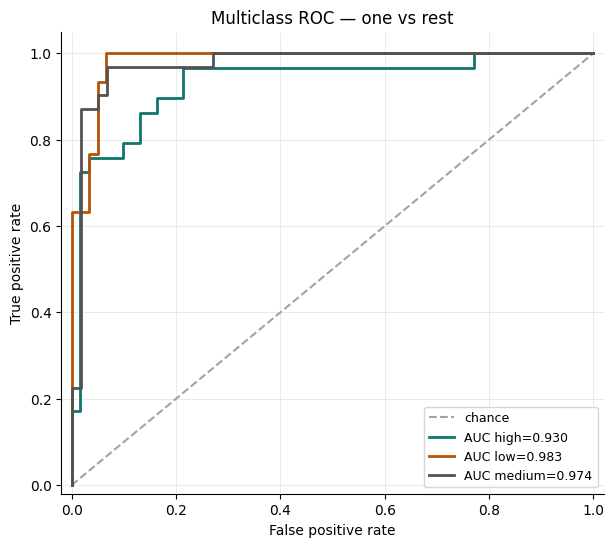

In [17]:
fig_multi_roc = plot_roc_curves(mc.model, mX_te, my_te, title="Multiclass ROC — one vs rest")

## 8 · Regression path

The same pipeline with a continuous pIC50 target: parity scatter against
the identity line, and residual diagnostics (vs predicted + histogram)
that the legacy scripts never drew.


In [18]:
from make_synthetic_qsar_data import make_regression_table

reg_table = make_regression_table(n_samples=260, seed=21)
reg_table.to_csv(WORK / "regression.csv", index=False)
ds_reg = load_dataset(WORK / "regression.csv")     # numeric target -> regression

print(ds_reg.summary())
print("task:", ds_reg.task, "| target:", ds_reg.target)

source        : /tmp/ml_workflow_plle23ro/regression.csv
shape         : 260 rows x 21 columns (20 numeric features)
target        : pIC50
task          : regression
missing cells : 0
dup. rows     : 0
task: regression | target: pIC50


In [19]:
rX_tr, rX_te, ry_tr, ry_te = make_train_test_split(ds_reg.X, ds_reg.y, test_size=0.25)

reg_result = train_model("random_forest", "regression", rX_tr, ry_tr, tune=False)
reg_report = evaluate_model(
    reg_result.model, rX_te, ry_te, "regression", keep_predictions=True
)
print(reg_report)

Class with 1 member(s) < 2 required; falling back to a non-stratified split.


rmse=1.9403  mae=1.5956  r2=0.7557  n=65


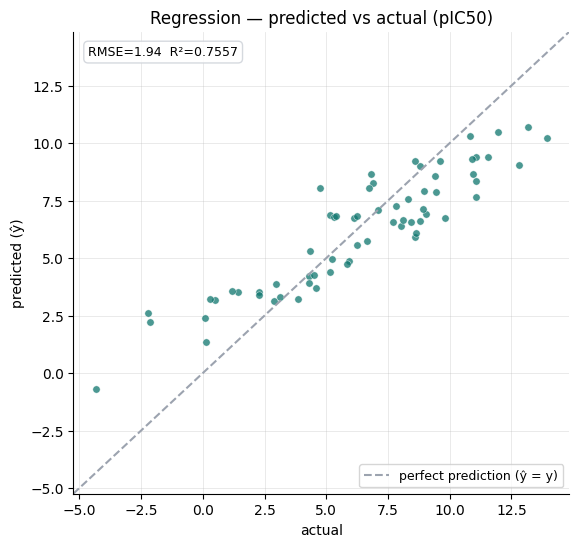

In [20]:
from pharmaml.viz import plot_predicted_vs_actual, plot_residuals

fig_parity = plot_predicted_vs_actual(
    ry_te, reg_report.predictions,
    metrics={"RMSE": reg_report.rmse, "R²": reg_report.r2},
    title="Regression — predicted vs actual (pIC50)",
)

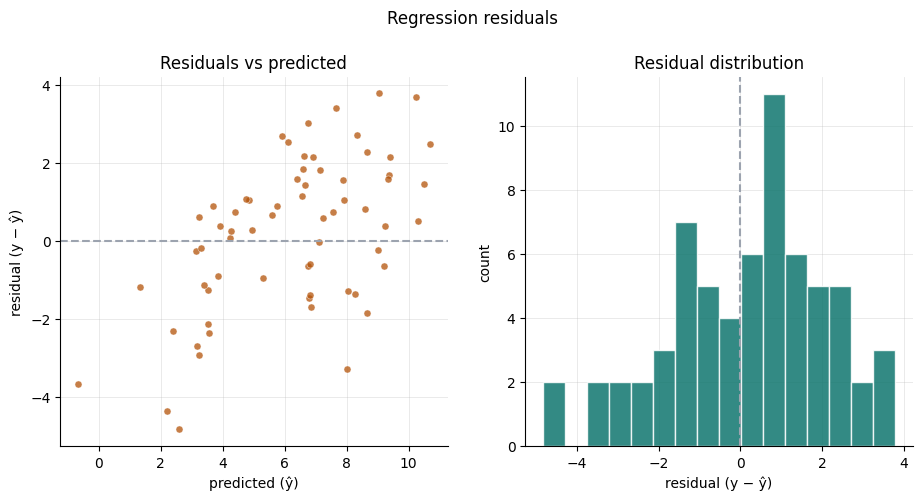

In [21]:
fig_residuals = plot_residuals(ry_te, reg_report.predictions, title="Regression residuals")

## 9 · Model leaderboard

`compare_models` cross-validates the whole registry at once — the job the
original archive spread over ~30 near-duplicate scripts. The error bars
are fold-to-fold standard deviations.


In [22]:
from pharmaml.ml import compare_models

leaderboard = compare_models(
    ds.X, ds.y, "classification",
    models=["logistic_regression", "knn", "random_forest", "decision_tree"],
    cv=5,
)
leaderboard.round(4)

,model,roc_auc_ovo_mean,roc_auc_ovo_std,fit_time_s,folds
0,logistic_regression,0.9960,0.0050,0.0056,5
1,random_forest,0.9311,0.0205,0.1276,5
2,knn,0.8728,0.0364,0.0042,5
3,decision_tree,0.8213,0.0358,0.0051,5


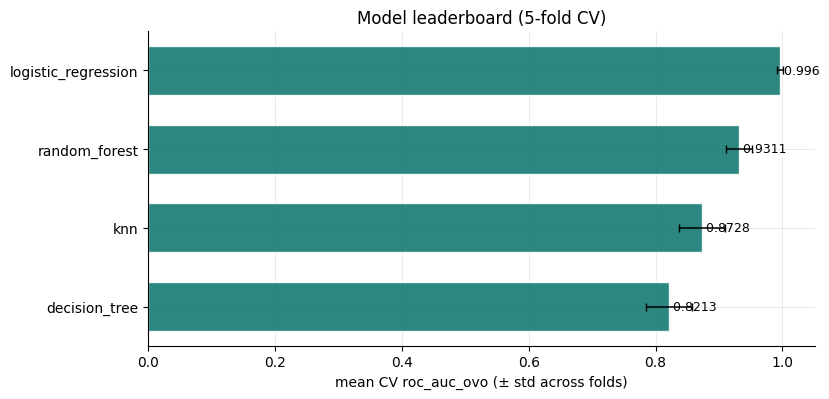

In [23]:
from pharmaml.viz import plot_model_comparison

fig_leaderboard = plot_model_comparison(leaderboard, title="Model leaderboard (5-fold CV)")

## 10 · Interpret — feature importance

Which descriptors drive the model? Works for tree ensembles
(`feature_importances_`), linear models (`|coef_|`) and explicit mappings.


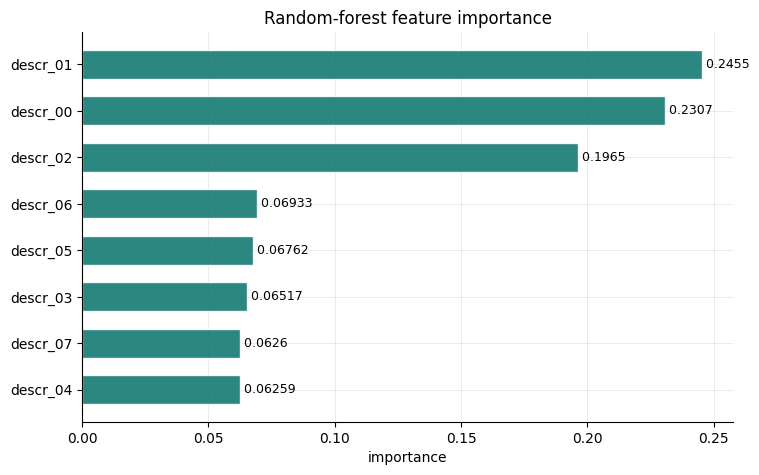

In [24]:
from pharmaml.viz import plot_feature_importance

fig_importance = plot_feature_importance(
    result.model, feature_names=ds.feature_names, top_n=8,
    title="Random-forest feature importance",
)

## 11 · Deploy — persistence and scoring new compounds

`save_model` writes a joblib bundle *with provenance metadata*; `load_model`
round-trips it. New, unseen rows are scored with one `predict` call.


In [25]:
from pharmaml.ml import save_model, load_model

MODEL_PATH = WORK / "rf_activity.joblib"
save_model(
    result.model, MODEL_PATH,
    name=result.name, task="classification",
    features=ds.feature_names, best_params=result.best_params,
    metrics=report.as_dict(),
)
loaded, metadata = load_model(MODEL_PATH)
print("reloaded:", metadata["name"], "| trained:", metadata["trained_at"])

reloaded: random_forest | trained: 2026-10-14T05:30:02+00:00


In [26]:
# Score five compounds the model has never seen.
new_rows = ds.X.sample(5, random_state=99)
predictions = loaded.predict(new_rows)

scored = pd.DataFrame({
    "compound_id": ds.frame.loc[new_rows.index, "compound_id"].values,
    "predicted_activity": predictions,
})
scored.to_csv(WORK / "scored_new_compounds.csv", index=False)
scored

,compound_id,predicted_activity
0,CMPD-0411,active
1,CMPD-0164,active
2,CMPD-0007,inactive
3,CMPD-0063,inactive
4,CMPD-0222,inactive


## 12 · Publish — the one-click visual bundle

`save_visual_bundle` renders every figure and table into a directory **and**
a self-contained `report.html` (figures embedded as base64 — no external
assets, renders identically offline). Tables are exported as csv *and*
markdown; figures as png *and* svg *and* pdf.


In [27]:
from pharmaml.viz import export_table, metrics_to_dataframe, save_visual_bundle

BUNDLE = WORK / "reports"
artifacts = save_visual_bundle(
    figures={
        "class_distribution": fig_balance,
        "cv_scores": fig_cv,
        "confusion_matrix": fig_confusion,
        "roc_curves": fig_roc,
        "parity_plot": fig_parity,
        "residuals": fig_residuals,
        "model_leaderboard": fig_leaderboard,
        "feature_importance": fig_importance,
    },
    tables={
        "metrics": metrics_to_dataframe(report),
        "leaderboard": leaderboard,
        "split_audit": split_audit,
        "scored_compounds": scored,
    },
    metrics=report,
    out_dir=BUNDLE,
    title="QSAR activity model — complete workflow",
    subtitle=f"{result.name} · {ds.n_samples} compounds · {len(ds.classes)} classes",
    formats=("png", "svg"),
    close=False,   # keep figures open so they also render above
)
pd.DataFrame({"artifact": [p.name for p in artifacts],
              "kind": [p.suffix.lstrip('.') for p in artifacts]})

,artifact,kind
0,report.html,html
1,metrics.csv,csv
2,metrics.md,md
3,leaderboard.csv,csv
4,leaderboard.md,md
5,split_audit.csv,csv
6,split_audit.md,md
7,scored_compounds.csv,csv
8,scored_compounds.md,md
9,class_distribution.png,png


In [28]:
# The same tables in every format a report could need.
exports = [
    export_table(leaderboard, BUNDLE / "leaderboard.md"),
    export_table(metrics_to_dataframe(report), BUNDLE / "metrics.json"),
    export_table(split_audit, BUNDLE / "split_audit.html"),
    export_table(scored, BUNDLE / "scored_new_compounds.tsv"),
]
[p.name for p in exports]

['leaderboard.md',
 'metrics.json',
 'split_audit.html',
 'scored_new_compounds.tsv']

In [29]:
# The self-contained report: open it in any browser — figures are embedded.
report_html = BUNDLE / "report.html"
size_kb = report_html.stat().st_size / 1024
print(f"{report_html}  ({size_kb:.0f} KB, zero external assets)")
print("First 3 lines:")
print("\n".join(report_html.read_text().splitlines()[:3]))

/tmp/ml_workflow_plle23ro/reports/report.html  (372 KB, zero external assets)
First 3 lines:
<!DOCTYPE html>
<html lang='en'>
<head>


## 13 · Recap

| Stage | One-liner |
|---|---|
| Import your data | `ds = load_dataset("my.csv", target="activity")` |
| Audit | `ds.summary()` |
| Convert endpoints | `add_pic50_column(frame, "IC50 (nM)")` |
| Split | `make_train_test_split(ds.X, ds.y, 0.2)` |
| Train | `train_model("random_forest", ds.task, Xtr, ytr)` |
| Evaluate | `evaluate_model(model, Xte, yte, ds.task)` |
| Compare | `compare_models(ds.X, ds.y, ds.task)` |
| Interpret | `plot_feature_importance(model, ds.feature_names)` |
| Deploy | `save_model(...)` / `load_model(path)` |
| Publish | `save_visual_bundle(figures, tables, metrics, "reports")` |
